# Linear static analysis of beams and frames

This example solves two linear static problems with the beam elements of
pyfe3d and compares the results with closed-form solutions:

1. an L-shaped frame of `BeamC` elements, clamped at the base of the column
   and loaded at the free end of the beam, in its plane and out of its plane;
2. the cantilever with shear deformation of Bathe (2014, Sec. 1.2), with
   `BeamC` and `BeamLR`.

The theory of the elements is in
[Beam theory and the beam elements](../beam_theory.rst), the orientation of
the element axes in [Conventions](../conventions.rst) and the steps of a
linear static analysis in [Linear static analyses](../linear_analyses.rst).
The full references are at the end of the notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix

from pyfe3d import (BeamC, BeamCData, BeamCProbe, BeamLR, BeamLRData,
                    BeamLRProbe, DOF, DOUBLE, INT)
from pyfe3d.beamprop import BeamProp
from pyfe3d.solver import solve

## 1. L-shaped frame

### Geometry, material and section

The column, of height $H = 3$ m, goes from the origin along the global $Y$
axis; the beam, of length $L = 2$ m, goes from the top of the column along
$X$. Both members have a rectangular section of width $b = 0.05$ m along the
element $z$ axis and height $h = 0.10$ m along the element $y$ axis, $E = 200$
GPa, $G = E/(2(1 + \nu))$ with $\nu = 0.3$, and the torsion constant $J = 1.5
\times 10^{-6}$ m$^4$. No shear correction factor is applied, so that $A$ is
also the shear area. The properties of the section are given to `BeamProp`:

In [2]:
H = 3.
L = 2.
P = 1.e3 # N, magnitude of the tip loads

E = 200.e9
nu = 0.3
b = 0.05 # width along the element z axis
h = 0.10 # height along the element y axis
prop = BeamProp()
prop.E = E
prop.G = E/(2*(1 + nu))
prop.A = b*h
prop.Izz = b*h**3/12
prop.Iyy = h*b**3/12
prop.J = 1.5e-6
print('A = %.4e m2, Izz = %.4e m4, Iyy = %.4e m4, J = %.4e m4'
      % (prop.A, prop.Izz, prop.Iyy, prop.J))

A = 5.0000e-03 m2, Izz = 4.1667e-06 m4, Iyy = 1.0417e-06 m4, J = 1.5000e-06 m4


### Mesh and stiffness matrix

Each element receives the positions `c1`, `c2` of its nodes in the global
vectors, `init_k_KC0`, its position in the sparse arrays of $\boldsymbol{K}_{C0}$,
and the vector `vxy` of `update_rotation_matrix`, which, with the element
axis, defines the element $x$-$y$ plane. The vector is chosen such that the
element $z$ axis of both members is the global $Z$ axis: the bending in the
plane of the frame is then governed by `Izz` and the bending out of its plane
by `Iyy`. The function below builds the frame with `num_elements` elements per
member and returns the elements and the global $\boldsymbol{K}_{C0}$,
assembled with `scipy.sparse.coo_matrix`:

In [3]:
def frame(num_elements):
    s = np.linspace(0, 1, num_elements + 1)
    column = np.column_stack((0*s, H*s, 0*s))
    beam = np.column_stack((L*s[1:], H + 0*s[1:], 0*s[1:]))
    ncoords = np.vstack((column, beam))
    x = ncoords.flatten()
    num_nodes = ncoords.shape[0]
    N = DOF*num_nodes

    data = BeamCData()
    probe = BeamCProbe()
    num_beams = num_nodes - 1
    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_beams, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_beams, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_beams, dtype=DOUBLE)
    elements = []
    for pos1 in range(num_beams):
        pos2 = pos1 + 1
        elem = BeamC(probe)
        elem.n1 = pos1 + 1
        elem.n2 = pos2 + 1
        elem.c1 = DOF*pos1
        elem.c2 = DOF*pos2
        elem.init_k_KC0 = pos1*data.KC0_SPARSE_SIZE
        if pos1 < num_elements:
            elem.update_rotation_matrix(-1., 0., 0., x) # column
        else:
            elem.update_rotation_matrix(0., 1., 0., x) # beam
        elem.update_probe_xe(x)
        elem.update_KC0(KC0r, KC0c, KC0v, prop)
        elements.append(elem)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    return ncoords, elements, KC0

### The reference solution

The displacements of the free end follow from the principle of virtual work
(the unit-load method), with the bending and shear deformations of the
Timoshenko beam, the axial deformation and the Saint-Venant torsion. For the
in-plane load $F_Y = -P$, the beam bends and shears, the column bends under
the constant moment $P L$ and shortens:

$$
v = -P \left(\frac{L^3}{3 E I_{zz}} + \frac{L}{G A}
    + \frac{L^2 H}{E I_{zz}} + \frac{H}{E A}\right), \qquad
u = \frac{P L H^2}{2 E I_{zz}}, \qquad
r_z = -P \left(\frac{L H}{E I_{zz}} + \frac{L^2}{2 E I_{zz}}\right)
$$

For the out-of-plane load $F_Z = P$, both members bend about their weak axis
and shear, and the column is twisted by the torque $P L$, which rotates the
beam as a rigid arm of length $L$:

$$
w = P \left(\frac{L^3 + H^3}{3 E I_{yy}} + \frac{L + H}{G A}
    + \frac{L^2 H}{G J}\right)
$$

The consistent shape functions of `BeamC` solve the equilibrium equations of
the Timoshenko beam for a prismatic element without distributed loads
(constant axial force, shear forces and twisting moment, linear bending
moments), so these nodal displacements are expected to be exact with any
number of elements per member, to round-off:

In [4]:
G, A = prop.G, prop.A
Izz, Iyy, J = prop.Izz, prop.Iyy, prop.J
v_ref = -P*(L**3/(3*E*Izz) + L/(G*A) + L**2*H/(E*Izz) + H/(E*A))
u_ref = P*L*H**2/(2*E*Izz)
rz_ref = -P*(L*H/(E*Izz) + L**2/(2*E*Izz))
w_ref = P*((L**3 + H**3)/(3*E*Iyy) + (L + H)/(G*A) + L**2*H/(G*J))
print('v_ref = %.6e m, u_ref = %.6e m, rz_ref = %.6e rad, w_ref = %.6e m'
      % (v_ref, u_ref, rz_ref, w_ref))

v_ref = -1.760820e-02 m, u_ref = 1.080000e-02 m, rz_ref = -9.600000e-03 rad, w_ref = 1.600130e-01 m


### Boundary conditions and solution

The six dofs of the first node, the base of the column, are constrained: the
Boolean array `bk` marks the known dofs and `bu` the unknown ones, and the
system $\boldsymbol{K}_{C0_{uu}} \boldsymbol{u}_u = \boldsymbol{f}_u$ is solved
with `pyfe3d.solver.solve`. The last node is the free end, whose dofs start at
`N - DOF`. Both load cases are solved with 1 and 4 elements per member:

In [5]:
results = {}
for num_elements in [1, 4]:
    ncoords, elements, KC0 = frame(num_elements)
    N = KC0.shape[0]
    bk = np.zeros(N, dtype=bool)
    bk[:DOF] = True
    bu = ~bk
    KC0uu = KC0[bu, :][:, bu]
    tip = N - DOF

    # in-plane load at the free end
    f_in = np.zeros(N)
    f_in[tip + 1] = -P
    u_in = np.zeros(N)
    u_in[bu] = solve(KC0uu, f_in[bu])

    # out-of-plane load at the free end
    f_out = np.zeros(N)
    f_out[tip + 2] = P
    u_out = np.zeros(N)
    u_out[bu] = solve(KC0uu, f_out[bu])

    results[num_elements] = dict(ncoords=ncoords, elements=elements,
                                 u_in=u_in, u_out=u_out, bu=bu, f_in=f_in,
                                 v=u_in[tip + 1], u=u_in[tip + 0],
                                 rz=u_in[tip + 5], w=u_out[tip + 2])

### Results against the reference

The displacements of the free end agree with the closed form to round-off
with one element per member, as expected:

In [6]:
print('%-9s %-3s %16s %16s %10s' % ('elements', 'dof', 'pyfe3d', 'reference',
                                    'rel. diff.'))
for num_elements, res in results.items():
    for name, ref in [('v', v_ref), ('u', u_ref), ('rz', rz_ref), ('w', w_ref)]:
        print('%-9d %-3s %16.9e %16.9e %10.1e'
              % (num_elements, name, res[name], ref, res[name]/ref - 1))

elements  dof           pyfe3d        reference rel. diff.
1         v   -1.760820000e-02 -1.760820000e-02   -1.2e-13
1         u    1.080000000e-02  1.080000000e-02   -1.9e-13
1         rz  -9.600000000e-03 -9.600000000e-03   -1.1e-13
1         w    1.600130000e-01  1.600130000e-01    2.0e-15
4         v   -1.760820000e-02 -1.760820000e-02   -1.6e-13
4         u    1.080000000e-02  1.080000000e-02   -2.4e-13
4         rz  -9.600000000e-03 -9.600000000e-03   -1.5e-13
4         w    1.600130000e-01  1.600130000e-01   -1.1e-12


### Internal forces and reactions

`update_fint` gives the internal force vector $\boldsymbol{F}_{int} =
\boldsymbol{K}_{C0} \boldsymbol{u}$, element by element, from the
displacements given to the probe with `update_probe_ue`. At the free dofs it
equals the external load; at the clamped base it is the support reaction,
which balances the load and its moment $P L$ about $Z$, i.e. $(F_X, F_Y, F_Z,
M_X, M_Y, M_Z) = (0, P, 0, 0, 0, P L)$ for the in-plane load case:

In [7]:
res = results[4]
fint = np.zeros(DOF*res['ncoords'].shape[0])
for elem in res['elements']:
    elem.update_probe_ue(res['u_in'])
    elem.update_fint(fint, prop)
reaction_ref = np.array([0, P, 0, 0, 0, P*L])
np.set_printoptions(precision=6, suppress=True)
print('reaction at the base    ', fint[:DOF])
print('expected                ', reaction_ref)
print('max |fint - fext| at the free dofs = %.2e N'
      % np.abs(fint[res['bu']] - res['f_in'][res['bu']]).max())

reaction at the base     [   0. 1000.    0.    0.    0. 2000.]
expected                 [   0. 1000.    0.    0.    0. 2000.]
max |fint - fext| at the free dofs = 1.82e-10 N


### Deformed shapes

The nodal displacements of the mesh with 4 elements per member, amplified
for the plot (the lines join the nodes, the element interpolation between
them is not drawn):

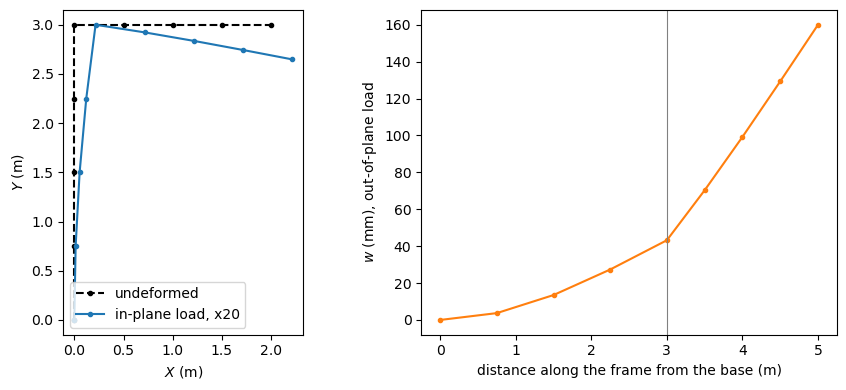

In [8]:
res = results[4]
X, Y, Z = res['ncoords'].T
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
scale = 20
uin = res['u_in']
axs[0].plot(X, Y, 'k--o', ms=3, label='undeformed')
axs[0].plot(X + scale*uin[0::DOF], Y + scale*uin[1::DOF], 'C0-o', ms=3,
            label='in-plane load, x%d' % scale)
axs[0].set_xlabel('$X$ (m)')
axs[0].set_ylabel('$Y$ (m)')
axs[0].set_aspect('equal')
axs[0].legend(loc='lower left')
uout = res['u_out']
s = np.r_[Y[:5], H + X[5:]]
axs[1].plot(s, uout[2::DOF]*1e3, 'C1-o', ms=3)
axs[1].axvline(H, color='gray', lw=0.8)
axs[1].set_xlabel('distance along the frame from the base (m)')
axs[1].set_ylabel('$w$ (mm), out-of-plane load')
plt.tight_layout()
plt.show()

## 2. Cantilever with shear deformation

The tip deflection of a cantilever under a tip force $W$, with the shear
deformation, is Eq. (1.2) of Bathe (2014, Sec. 1.2, p. 5),

$$
\delta = \frac{W L^3}{3 E I} + \frac{W L}{\kappa G A}
$$

for the beam of his Fig. 1.2(b): $L = 28$ cm (the length plus $r_N$ of the
figure), height 6 cm, thickness 0.4 cm, $E = 2 \times 10^7$ N/cm$^2$, $\nu =
0.3$, $\kappa = 5/6$ and $W = 1000$ N, for which Bathe gives 0.053 cm. The
shear correction factor is included in $G$. The section is square in
stiffness, `Izz = Iyy`, so the deflections in both bending planes are equal:

In [9]:
Lc = 28. # cm
W = 1000. # N
Ec = 2.e7 # N/cm2
hc = 6. # cm
tc = 0.4 # cm
propc = BeamProp()
propc.A = hc*tc
propc.E = Ec
propc.G = 5/6*Ec/(2*(1 + 0.3))
propc.Izz = propc.Iyy = tc*hc**3/12
propc.J = propc.Izz + propc.Iyy

delta_ref = W*Lc**3/(3*Ec*propc.Izz) + W*Lc/(propc.A*propc.G)
print('Eq. (1.2) of Bathe (2014): delta = %.7f cm' % delta_ref)

Eq. (1.2) of Bathe (2014): delta = 0.0526348 cm


The cantilever is meshed along $x$ with `BeamC` or `BeamLR` elements, clamped
at $x = 0$, and the tip deflections along $y$ and $z$ are computed for unit
tip forces:

In [10]:
ELEMENTS = {
    'BeamC': (BeamC, BeamCData, BeamCProbe),
    'BeamLR': (BeamLR, BeamLRData, BeamLRProbe),
}

def cantilever_tip(name, num_elements):
    cls, datacls, probecls = ELEMENTS[name]
    data = datacls()
    probe = probecls()
    xs = np.linspace(0, Lc, num_elements + 1)
    x = np.vstack((xs, 0*xs, 0*xs)).T.flatten()
    N = DOF*(num_elements + 1)
    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    for i in range(num_elements):
        beam = cls(probe)
        beam.init_k_KC0 = i*data.KC0_SPARSE_SIZE
        beam.n1, beam.n2 = i + 1, i + 2
        beam.c1, beam.c2 = DOF*i, DOF*(i + 1)
        beam.update_rotation_matrix(0., 1., 0., x)
        beam.update_probe_xe(x)
        beam.update_KC0(KC0r, KC0c, KC0v, propc)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    bu = np.ones(N, dtype=bool)
    bu[:DOF] = False
    tip = []
    for direction in [1, 2]:
        f = np.zeros(N)
        f[N - DOF + direction] = 1.
        u = np.zeros(N)
        u[bu] = solve(KC0[bu, :][:, bu], f[bu])
        tip.append(u[N - DOF + direction])
    return np.array(tip)

`BeamC` is exact with one element, for the reason given for the frame.
`BeamLR`, with its linear interpolation and reduced integration, converges
with the square of the element length:

In [11]:
print('%-7s %8s %12s %12s %12s %11s %11s' % ('element', 'elements',
      'delta_y', 'delta_z', 'Eq. (1.2)', 'rel. diff.', 'vs 0.053'))
for name, num_elements in [('BeamC', 1), ('BeamC', 3), ('BeamLR', 10),
                           ('BeamLR', 100)]:
    dy, dz = W*cantilever_tip(name, num_elements)
    print('%-7s %8d %12.7f %12.7f %12.7f %11.2e %11.2e'
          % (name, num_elements, dy, dz, delta_ref, dy/delta_ref - 1,
             dy/0.053 - 1))

element elements      delta_y      delta_z    Eq. (1.2)  rel. diff.    vs 0.053
BeamC          1    0.0526348    0.0526348    0.0526348   -2.22e-16   -6.89e-03
BeamC          3    0.0526348    0.0526348    0.0526348   -1.55e-15   -6.89e-03
BeamLR        10    0.0525078    0.0525078    0.0526348   -2.41e-03   -9.29e-03
BeamLR       100    0.0526335    0.0526335    0.0526348   -2.41e-05   -6.91e-03


The last column compares with the published value, 0.053 cm, given with two
significant digits. The convergence of `BeamLR`:

BeamLR    4 elements, relative difference 1.508e-02
BeamLR    8 elements, relative difference 3.771e-03
BeamLR   16 elements, relative difference 9.428e-04
BeamLR   32 elements, relative difference 2.357e-04
BeamLR   64 elements, relative difference 5.892e-05
BeamLR  128 elements, relative difference 1.473e-05
fitted order of convergence: 2.00


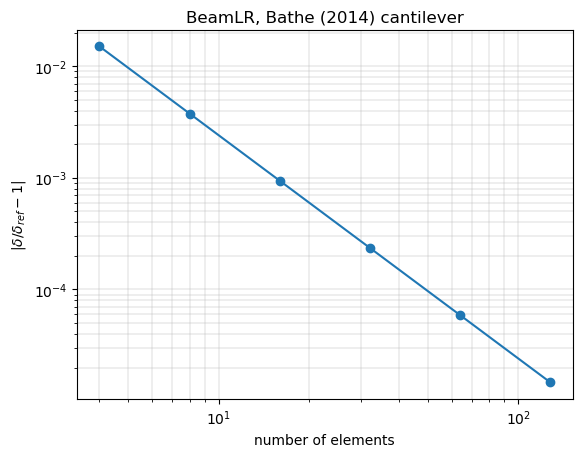

In [12]:
nes = np.array([4, 8, 16, 32, 64, 128])
errors = np.array([abs(W*cantilever_tip('BeamLR', ne)[0]/delta_ref - 1)
                   for ne in nes])
for ne, err in zip(nes, errors):
    print('BeamLR %4d elements, relative difference %.3e' % (ne, err))
rate = np.polyfit(np.log(1/nes), np.log(errors), 1)[0]
print('fitted order of convergence: %.2f' % rate)

plt.loglog(nes, errors, 'o-')
plt.xlabel('number of elements')
plt.ylabel(r'$|\delta/\delta_{ref} - 1|$')
plt.title('BeamLR, Bathe (2014) cantilever')
plt.grid(True, which='both', lw=0.3)
plt.show()

## References

- Bathe, K. J., Finite Element Procedures, 2nd ed., K. J. Bathe, Watertown,
  MA, 2014, ISBN 978-0-9790049-5-7.